In [1]:
import io
import os
import random
import sys
sys.path.insert(0, os.path.dirname(os.path.abspath(os.getcwd())))


In [2]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from IPython.display import Image, display
from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor


In [3]:
from src.adagrad import AdagradScratch
from src.covers import cover_memory, tensor_cover
from src.sm3 import SM3Scratch
from src.sm3ii import SM3IIScratch
from src.warmup import QuadraticWarmup


In [4]:
torch.manual_seed(0)
random.seed(0)
np.random.seed(0)


In [5]:
def cover_for(p):
    if p.dim() == 0 or p.numel() == 0:
        return [[0]]
    cover = tensor_cover(tuple(p.shape))
    return cover if len(cover) > 0 else [[0]]
def show(fig):
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=110)
    plt.close(fig)
    display(Image(data=buf.getvalue()))


In [6]:
batch_size = 64
data_root = "data" if os.path.isdir("data") else "src/data"
training_set = MNIST(root=data_root, train=True, download=False, transform=ToTensor())
training_loader = torch.utils.data.DataLoader(dataset=training_set, batch_size=batch_size, shuffle=True)
testing_set = MNIST(root=data_root, train=False, download=False, transform=ToTensor())
testing_loader = torch.utils.data.DataLoader(dataset=testing_set, batch_size=batch_size, shuffle=False)


In [7]:
class TorchSM3II:
    def __init__(self, params, lr=0.1):
        self.params = list(params)
        self.opt = []
        for p in self.params:
            o = SM3IIScratch(p.numel(), cover_for(p), lr)
            o.w = p.detach().cpu().numpy().ravel().astype(float).copy()
            self.opt.append(o)
    @property
    def lr(self):
        return self.opt[0].eta
    @lr.setter
    def lr(self, v):
        for o in self.opt:
            o.eta = float(v)
    def step(self, grads):
        for p, g, o in zip(self.params, grads, self.opt):
            w = o.step(g.detach().cpu().numpy().ravel())
            p.data.copy_(torch.from_numpy(w.reshape(tuple(p.shape))).to(p.data.dtype))


In [8]:
model = nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 10))
print([cover_memory(tuple(p.shape)) for p in model.parameters() if p.dim() > 0])
sched = QuadraticWarmup(500, 0.1)
opt = TorchSM3II(model.parameters(), lr=0.1)
loss_fn = nn.CrossEntropyLoss()
loss_hist = []
lr_hist = []
fc2_traj = []
gamma_fc1 = None
params_list = list(model.parameters())
step = 0
total = 0.0
for x, y in training_loader:
    model.zero_grad()
    loss = loss_fn(model(x), y)
    loss.backward()
    opt.lr = sched.lr(step)
    step += 1
    g0 = params_list[0].grad.detach().cpu().numpy().ravel().copy()
    g2 = params_list[2].grad.detach().cpu().numpy().ravel().copy()
    if gamma_fc1 is None:
        gamma_fc1 = np.zeros_like(g0, dtype=float)
    gamma_fc1 += g0 ** 2
    fc2_traj.append(g2)
    opt.step([p.grad for p in params_list])
    loss_hist.append(loss.item())
    lr_hist.append(opt.lr)
    total += loss.item()
print(float(total) / len(training_loader))


[(100352, 912), (128, 128), (1280, 138), (10, 10)]


0.5979308876703416


total full=101770 total cover=1188 ratio=85.7x


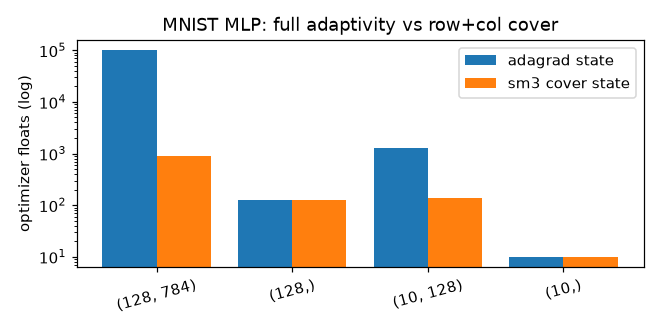

In [9]:
shapes = [tuple(p.shape) for p in model.parameters() if p.dim() > 0]
labels = [str(s) for s in shapes]
full = [cover_memory(s)[0] for s in shapes]
small = [cover_memory(s)[1] for s in shapes]
print(f"total full={sum(full)} total cover={sum(small)} ratio={sum(full)/sum(small):.1f}x")
fig, ax = plt.subplots(figsize=(6, 3))
x = range(len(shapes))
ax.bar([i - 0.2 for i in x], full, width=0.4, label="adagrad state")
ax.bar([i + 0.2 for i in x], small, width=0.4, label="sm3 cover state")
ax.set_yscale("log")
ax.set_xticks(list(x), labels, rotation=15)
ax.set_ylabel("optimizer floats (log)")
ax.set_title("MNIST MLP: full adaptivity vs row+col cover")
ax.legend()
fig.tight_layout()
show(fig)


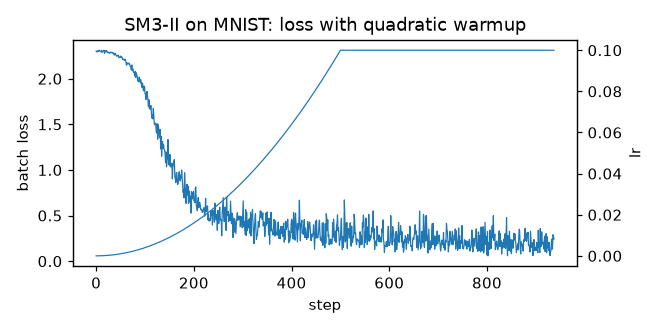

steps=938 final avg100=0.1982


In [10]:
fig, ax1 = plt.subplots(figsize=(6, 3))
ax1.plot(range(len(loss_hist)), loss_hist, linewidth=0.8)
ax1.set_xlabel("step")
ax1.set_ylabel("batch loss")
ax1.set_title("SM3-II on MNIST: loss with quadratic warmup")
ax2 = ax1.twinx()
ax2.plot(range(len(lr_hist)), lr_hist, linewidth=0.8)
ax2.set_ylabel("lr")
fig.tight_layout()
show(fig)
print(f"steps={len(loss_hist)} final avg100={sum(loss_hist[-100:])/100:.4f}")


top1 adagrad=2.164 sm3=2.843 sm3ii=2.227


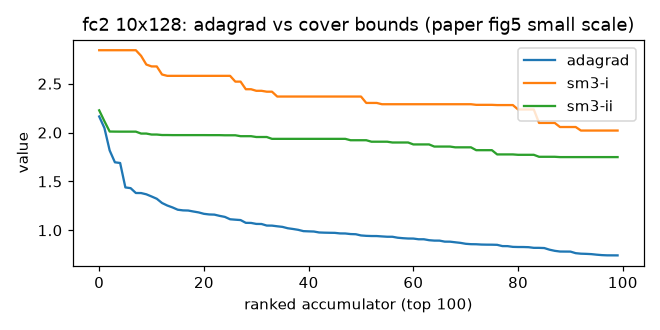

In [11]:
cover_fc2 = tensor_cover((10, 128))
a = AdagradScratch(1280)
b = SM3Scratch(1280, cover_fc2)
c = SM3IIScratch(1280, cover_fc2)
for g in fc2_traj:
    a.step(g); b.step(g); c.step(g)
nu_ad = a.gamma
nu1 = np.full(1280, np.inf)
for r, s in enumerate(b.cover):
    nu1[s] = np.minimum(nu1[s], b.mu[r])
nu2 = np.full(1280, np.inf)
for r, s in enumerate(c.cover):
    nu2[s] = np.minimum(nu2[s], c.mu_prev[r])
top = 100
sa = np.sort(nu_ad)[::-1][:top]
s1 = np.sort(nu1)[::-1][:top]
s2 = np.sort(nu2)[::-1][:top]
print(f"top1 adagrad={sa[0]:.3f} sm3={s1[0]:.3f} sm3ii={s2[0]:.3f}")
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(sa, label="adagrad")
ax.plot(s1, label="sm3-i")
ax.plot(s2, label="sm3-ii")
ax.set_xlabel("ranked accumulator (top 100)")
ax.set_ylabel("value")
ax.set_title("fc2 10x128: adagrad vs cover bounds (paper fig5 small scale)")
ax.legend()
fig.tight_layout()
show(fig)


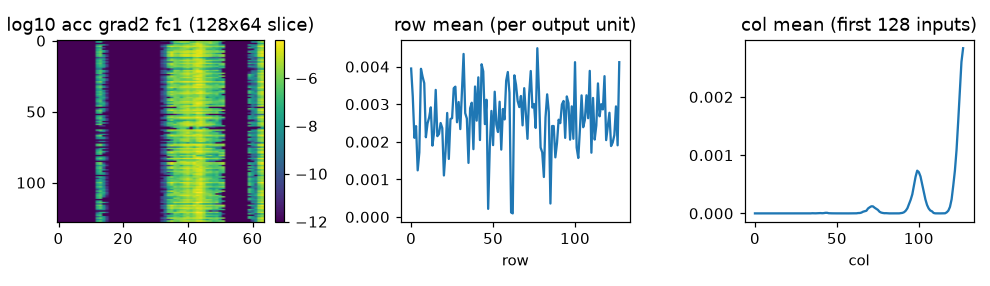

row std/mean=0.32 col std/mean=1.35


In [12]:
W = gamma_fc1.reshape(128, 784)
row = W.mean(axis=1)
col = W.mean(axis=0)
fig, ax = plt.subplots(1, 3, figsize=(9, 2.6))
im = ax[0].imshow(np.log10(W[:, :64] + 1e-12), aspect="auto")
ax[0].set_title("log10 acc grad2 fc1 (128x64 slice)")
fig.colorbar(im, ax=ax[0], fraction=0.046)
ax[1].plot(row)
ax[1].set_title("row mean (per output unit)")
ax[1].set_xlabel("row")
ax[2].plot(col[:128])
ax[2].set_title("col mean (first 128 inputs)")
ax[2].set_xlabel("col")
fig.tight_layout()
show(fig)
print(f"row std/mean={row.std()/(row.mean()+1e-12):.2f} col std/mean={col.std()/(col.mean()+1e-12):.2f}")


adagrad avg=0.4933 last100=0.1448 acc=0.9560


sm3 avg=0.6015 last100=0.2010 acc=0.9472


sm3ii avg=0.5989 last100=0.1984 acc=0.9483


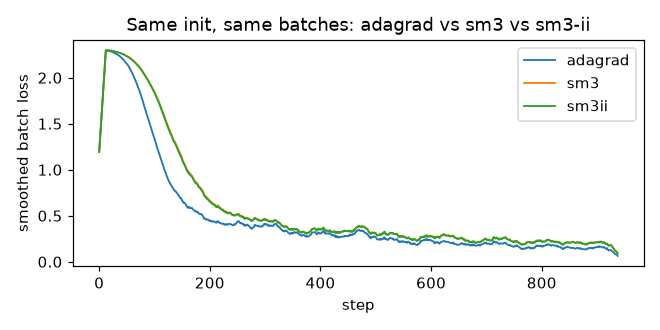

In [13]:
def _loader(seed=0):
    g = torch.Generator()
    g.manual_seed(seed)
    tr = MNIST(root=data_root, train=True, download=False, transform=ToTensor())
    te = MNIST(root=data_root, train=False, download=False, transform=ToTensor())
    return (torch.utils.data.DataLoader(tr, batch_size=64, shuffle=True, generator=g),
            torch.utils.data.DataLoader(te, batch_size=512, shuffle=False))
def _build(kind, params, lr=0.1):
    opts = []
    for p in params:
        if kind == "adagrad":
            o = AdagradScratch(p.numel(), lr)
        elif kind == "sm3":
            o = SM3Scratch(p.numel(), cover_for(p), lr)
        else:
            o = SM3IIScratch(p.numel(), cover_for(p), lr)
        o.w = p.detach().cpu().numpy().ravel().astype(float).copy()
        opts.append(o)
    return opts
torch.manual_seed(0); random.seed(0); np.random.seed(0)
_base = nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 10))
_init = {k: v.clone() for k, v in _base.state_dict().items()}
results = {}
for kind in ["adagrad", "sm3", "sm3ii"]:
    torch.manual_seed(0); random.seed(0); np.random.seed(0)
    m = nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 10))
    m.load_state_dict(_init)
    plist = list(m.parameters())
    tr_ld, te_ld = _loader(seed=0)
    opts = _build(kind, plist)
    sch = QuadraticWarmup(500, 0.1)
    lf = nn.CrossEntropyLoss()
    hist = []
    st = 0
    for x, y in tr_ld:
        m.zero_grad()
        lo = lf(m(x), y)
        lo.backward()
        lr = sch.lr(st)
        st += 1
        for o in opts:
            o.eta = float(lr)
        for p, g, o in zip(plist, [p.grad for p in plist], opts):
            w = o.step(g.detach().cpu().numpy().ravel())
            p.data.copy_(torch.from_numpy(w.reshape(tuple(p.shape))).to(p.data.dtype))
        hist.append(lo.item())
    corr = tot = 0
    with torch.no_grad():
        for x, y in te_ld:
            corr += int((m(x).argmax(1) == y).sum())
            tot += y.numel()
    results[kind] = (hist, corr / tot)
    print(f"{kind} avg={sum(hist)/len(hist):.4f} last100={sum(hist[-100:])/100:.4f} acc={corr/tot:.4f}")
def _sm(v, w=25):
    return np.convolve(v, np.ones(w)/w, mode="same")
fig, ax = plt.subplots(figsize=(6, 3))
for kind in ["adagrad", "sm3", "sm3ii"]:
    ax.plot(_sm(np.array(results[kind][0])), label=kind, linewidth=1.2)
ax.set_xlabel("step")
ax.set_ylabel("smoothed batch loss")
ax.set_title("Same init, same batches: adagrad vs sm3 vs sm3-ii")
ax.legend()
fig.tight_layout()
show(fig)


In [14]:
correct = 0
count = 0
with torch.no_grad():
    for x, y in testing_loader:
        pred = model(x).argmax(dim=1)
        correct += int((pred == y).sum())
        count += y.numel()
print(float(correct) / float(count))


0.9421
